# Shapes3D → five-block ViT-Tiny → the repository's SAE tracking pipeline

Train a small classifier on four Shapes3D shape classes, export its representations,
fit independent SAEs, run the repository's combined evaluator, and aggregate its saved
evolution patterns. The default backbone uses **five blocks, width 192, and three heads**.
All computation is on CPU; the configuration cell controls data size, width, depth and epochs.

**This notebook follows the pipeline's files and call signatures.** It writes raw activation
`.npy` files, reads them with `src.utils.load_all_data`, uses `_checkpoint_path` for SAE
filenames, calls `_evaluate_run_combined` to write its existing `.npz` format, and lets
`_save_concept_evo_pattern` and `compute_scores_for_reference_grid` reload those files.
The evaluator's matching logic, return value and artifact keys are unchanged.

This is a small teaching experiment, not a reproduction of ImageNet results. 

*At each section, the commands and config files are pointed at, how to reproduce the full ImageNet experiment pipeline are given after "**FULL MODE:**"*

**FULL MODE:**
```
# ImageNet-1K: ViT training -> activation export -> SAE training -> combined evolution patterns -> evaluation -> pattern plots -> aggregate tables/heatmaps.
```
| Stage | Existing implementation |
| --- | --- |
| ViT training | `vit_tiny_imagenet_train_ffcv.py` |
| `export` | `generate_acts_vit_fun_tiny.generate_acts_vit` |
| `sae` | `sae_track_method.train_sae_grid`, with `train_sae_fast` |
| `evaluate` | `sae_track_method._evaluate_run_combined` |
| `plot` | `sae_track_method._save_concept_evo_pattern` |
| `aggregate` | `compute_scores_for_reference_grid`, `plot_aggregate_heatmaps` |





## 1. Environment and imports

Use **Python 3.10** and `requirements_tutorial.txt`. It pins the
notebook's direct dependencies to the versions used for CPU validation. The existing
`requirements.txt` is a separate Conda export for the larger pipeline.

From this repository, in a Python 3.10 environment:

```bash
python -m pip install torch==1.13.0+cpu torchvision==0.14.0+cpu --extra-index-url https://download.pytorch.org/whl/cpu
python -m pip install -r requirements_tutorial.txt
python -m pip check
python -m ipykernel install --user --name shapes3d-cpu --display-name "Shapes3D CPU"
python -m jupyterlab
```

**FULL MODE:**
```bash
pip install -r requirements.txt
```

In [9]:
import ast
import contextlib
import inspect
import io
import json
import math
import os
import platform
import random
import sys
import tempfile
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
import timm
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import yaml
from PIL import Image as PILImage
from IPython.display import display, Image as NotebookImage
from IPython.utils.capture import capture_output

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "base_sae.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside this repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils import load_all_data, feature_normalize
import sae_track_method as tracking
import evo_aggregate_patterns as repo_metrics
from generate_acts_vit_fun_tiny import collect_hidden_states_timm
from src.sae_utils import (
    train_sae_fast, load_checkpoint, get_saes_similarities,
    concept_summary_stats, plot_metrics_figure,
)
print("Repository:", ROOT)
print("Python", platform.python_version(), "| torch", torch.__version__, "| timm", timm.__version__)


Repository: c:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration
Python 3.8.19 | torch 1.13.1 | timm 1.0.30


## 2. Speed controls

Reduce `depth`, `embed_dim`, samples, epochs or SAE expansion
for a shorter run; width must be divisible by the number of attention heads.

Keep at least two positive checkpoint epochs for feature tracking.
The all-reference stage compares every reference with every target; reducing this
grid can save much more work than reducing classifier epochs alone.
`all_reference_analysis=False` aggregates only the final reference. Feature tracking
may create a few additional reference files for its selected feature's plots.

For a job, set `SHAPES3D_PROFILE=smoke`, or use `SHAPES3D_CONFIG_JSON`, for example:

```json
{"depth":3,"embed_dim":96,"vit_epochs":4,"checkpoint_epochs":[1,2,4],"sae_epochs":10,"sae_expansion":2,"all_reference_analysis":false}
```

These settings override `CFG` after the selected profile. `SHAPES3D_CPU_THREADS`,
`SHAPES3D_DATA_PATH` and `SHAPES3D_OUTPUT_ROOT` optionally control resources and paths.
Each Run All creates a fresh directory; the full demo has 12 checkpoints × 5 layers
= 60 SAEs and 60 reference evaluations. Use the smoke profile before a long job.

**FULL MODE:**

Prepare the experiment settings in `sae_exp_config_base.yml`

In [ ]:
PROFILE = os.environ.get('SHAPES3D_PROFILE', 'smoke')  # 'demo' or 'smoke'
CFG = dict(
    seed=42, depth=5, embed_dim=192, num_heads=3,
    image_size=64, batch_size=64, cpu_threads=min(4, os.cpu_count() or 1),
    n_train=4096, n_val=512, n_analysis=2048,
    n_sae_train=2048, n_sae_val=256,
    vit_epochs=12, checkpoint_epochs=list(range(1, 13)),
    vit_lr=5e-4, weight_decay=0.01,
    sae_epochs=40, sae_expansion=5, sae_k=16, sae_batch_size=256,
    sae_lr=0.003, sae_z_l2=0.05,
    all_reference_analysis=True, pattern_images=True, track_steps=2,
)
if PROFILE == 'smoke':
    CFG.update(n_train=128, n_val=64, n_analysis=64,
               n_sae_train=128, n_sae_val=64,
               vit_epochs=2, checkpoint_epochs=[1, 2], sae_epochs=3, sae_expansion=2)
elif PROFILE != 'demo':
    raise ValueError("PROFILE must be 'demo' or 'smoke'")

# Optional overrides: uncomment before Run All, for example.
# CFG.update(depth=3, embed_dim=96, vit_epochs=4,
#            checkpoint_epochs=[1, 2, 4], sae_epochs=15)

overrides = json.loads(os.environ.get('SHAPES3D_CONFIG_JSON', '{}'))
if not isinstance(overrides, dict) or set(overrides) - set(CFG):
    raise ValueError('SHAPES3D_CONFIG_JSON must be an object containing existing CFG keys.')
CFG.update(overrides)
if 'SHAPES3D_CPU_THREADS' in os.environ:
    CFG['cpu_threads'] = int(os.environ['SHAPES3D_CPU_THREADS'])
if CFG['depth'] < 1 or CFG['embed_dim'] % CFG['num_heads']:
    raise ValueError('Use depth >= 1 and embed_dim divisible by num_heads.')
if CFG['n_sae_train'] > CFG['n_train'] or CFG['n_sae_val'] > CFG['n_val']:
    raise ValueError('SAE subset sizes must not exceed their source split sizes.')
if CFG['vit_epochs'] < 2 or CFG['sae_epochs'] < 1 or CFG['cpu_threads'] < 1:
    raise ValueError('Use vit_epochs >= 2, sae_epochs >= 1 and cpu_threads >= 1.')
if not 0 < CFG['sae_k'] <= CFG['embed_dim'] * CFG['sae_expansion']:
    raise ValueError('sae_k must fit in the SAE code dimension.')
if not isinstance(CFG['track_steps'], int) or CFG['track_steps'] < 1:
    raise ValueError('track_steps must be a positive integer.')

EPOCHS = sorted(set([CFG['vit_epochs']] + [int(e) for e in CFG['checkpoint_epochs']
                  if 1 <= e <= CFG['vit_epochs']]))
if len(EPOCHS) < 2:
    raise ValueError('Save at least two positive checkpoint epochs for _track_feature.')
LAYERS = list(range(CFG['depth']))
REF = (EPOCHS[-1], LAYERS[-1])
DEVICE = torch.device('cpu')              # Explicitly CPU, even on a GPU machine.
torch.set_num_threads(CFG['cpu_threads'])

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_all(CFG['seed'])
DATA_PATH = Path(os.environ.get('SHAPES3D_DATA_PATH', ROOT / 'data' / 'shapes3d' / '3dshapes.h5')).expanduser().resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Expected local Shapes3D file: {DATA_PATH}')
OUTPUT_ROOT = Path(os.environ.get('SHAPES3D_OUTPUT_ROOT', ROOT / 'demo_outputs' / 'shapes3d_cpu')).expanduser().resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix=PROFILE + '_', dir=OUTPUT_ROOT))
for name in ('vit', 'activations', 'analysis', 'figures', 'logs', 'images', 'imglists'):
    (RUN_DIR / name).mkdir()
(RUN_DIR / 'config.json').write_text(json.dumps(dict(CFG, epochs=EPOCHS, layers=LAYERS), indent=2))
VERSIONS = dict(python=platform.python_version(), torch=torch.__version__, timm=timm.__version__,
                numpy=np.__version__, scipy=scipy.__version__, h5py=h5py.__version__)
(RUN_DIR / 'versions.json').write_text(json.dumps(VERSIONS, indent=2))
TIMES = {}
NOTEBOOK_START = time.perf_counter()
print(json.dumps(CFG, indent=2))
print(f'{len(EPOCHS)} checkpoints × {len(LAYERS)} layers = {len(EPOCHS)*len(LAYERS)} SAEs')
print('Reference (epoch, layer):', REF, '| output:', RUN_DIR)


{
  "seed": 42,
  "depth": 5,
  "embed_dim": 192,
  "num_heads": 3,
  "image_size": 64,
  "batch_size": 64,
  "cpu_threads": 4,
  "n_train": 128,
  "n_val": 64,
  "n_analysis": 64,
  "n_sae_train": 128,
  "n_sae_val": 64,
  "vit_epochs": 2,
  "checkpoint_epochs": [
    1,
    2
  ],
  "vit_lr": 0.0005,
  "weight_decay": 0.01,
  "sae_epochs": 3,
  "sae_expansion": 2,
  "sae_k": 16,
  "sae_batch_size": 256,
  "sae_lr": 0.003,
  "sae_z_l2": 0.05,
  "all_reference_analysis": true,
  "pattern_images": true,
  "track_steps": 2
}
2 checkpoints × 5 layers = 10 SAEs
Reference (epoch, layer): (2, 4) | output: C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4


## 3. Load a reproducible, disjoint Shapes3D sample

Classification predicts the four-valued **shape** factor. Train, validation and analysis
images are disjoint. The pipeline calls the analysis split `test`; it is not used for
classifier or SAE fitting.

**FULL MODE:**

Prepare a folder with the e.g. ImageNet-1k images and split.txt files and add the directory path to the .yml
```bash
data_dir: /gpfs/space/projects/mlgroup/data/images_largescale/ #/tmp/imagenet_1k/
imglist_path: /gpfs/space/projects/mlgroup/data/benchmark_imglist/imagenet/test_imagenet.txt #train_imagenet.txt
```
For full GPU utilization (in case of V100, H100) training the ViT-Tiny, using ffcv and .beton files stored on the machine is suggeted. In that case, run these with appropriate arguments and paths:
```bash
python build_imagenet_beton_from_imglist.py \
  --data-root /tmp/imagenet_1k \
  --imglist /gpfs/space/projects/mlgroup/data/benchmark_imglist/imagenet/train_imagenet.txt \
  --output /tmp/imagenet_1k/train_raw_256.beton \
  --write-mode raw \
  --max-resolution 256 \
  --num-workers 16

python build_imagenet_beton_from_imglist.py \
  --data-root /tmp/imagenet_1k \
  --imglist /gpfs/space/projects/mlgroup/data/benchmark_imglist/imagenet/test_imagenet.txt \
  --output /tmp/imagenet_1k/val_raw_256.beton \
  --write-mode raw \
  --max-resolution 256 \
  --num-workers 16


```

{'images': ((480000, 64, 64, 3), 'uint8'), 'labels': ((480000, 6), 'float64')}
Read image slabs: 8/32
Read image slabs: 16/32
Read image slabs: 24/32
Read image slabs: 32/32


,train,val,analysis
shape ID,,,
0,32,16,16
1,32,16,16
2,32,16,16
3,32,16,16


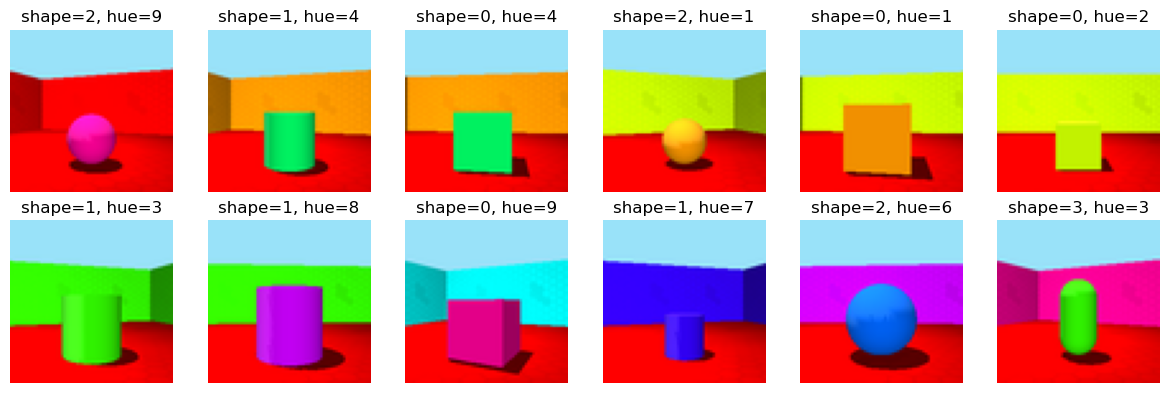

Data loading: 57.8s


In [14]:
t0 = time.perf_counter()
FACTOR_NAMES = ['floor_hue', 'wall_hue', 'object_hue', 'scale', 'shape', 'orientation']
with h5py.File(DATA_PATH, 'r') as f:
    print({name: (f[name].shape, str(f[name].dtype)) for name in ('images', 'labels')})
    raw_factors = f['labels'][:]
factor_values, factor_ids = [], np.empty(raw_factors.shape, dtype=np.int64)
for j in range(6):
    values, ids = np.unique(raw_factors[:, j], return_inverse=True)
    factor_values.append(values)
    factor_ids[:, j] = ids
shape_ids = factor_ids[:, 4]
n_total = CFG['n_train'] + CFG['n_val'] + CFG['n_analysis']
pool, _ = train_test_split(np.arange(len(shape_ids)), train_size=n_total,
                          stratify=shape_ids, random_state=CFG['seed'])
train_idx, rest = train_test_split(pool, train_size=CFG['n_train'], stratify=shape_ids[pool],
                                 random_state=CFG['seed'] + 1)
val_idx, analysis_idx = train_test_split(rest, train_size=CFG['n_val'], stratify=shape_ids[rest],
                                       random_state=CFG['seed'] + 2)
SPLIT_IDS = dict(train=np.sort(train_idx), val=np.sort(val_idx), analysis=np.sort(analysis_idx))
joined = np.concatenate(list(SPLIT_IDS.values()))
np.savez(RUN_DIR / 'split_indices.npz', **SPLIT_IDS)
np.savez(RUN_DIR / 'factor_values.npz', **dict(zip(FACTOR_NAMES, factor_values)))

def read_selected_images(path, indices):
    indices = np.sort(np.asarray(indices))
    selected = np.empty((len(indices), 64, 64, 3), dtype=np.uint8)
    with h5py.File(path, 'r') as f:
        ds = f['images']
        stride = ds.chunks[0] if ds.chunks else 2048
        for start in range(0, ds.shape[0], stride):
            lo, hi = np.searchsorted(indices, [start, start + stride])
            if hi > lo:
                slab = ds[start:min(start + stride, ds.shape[0])]
                selected[lo:hi] = slab[indices[lo:hi] - start]
                del slab
            if (start // stride + 1) % 8 == 0:
                print(f'Read image slabs: {start // stride + 1}/{math.ceil(ds.shape[0]/stride)}')
    return selected

all_selected_ids = np.sort(joined)
selected_rgb = read_selected_images(DATA_PATH, all_selected_ids)
RGB, X, Y, FACTORS = {}, {}, {}, {}
for split, ids in SPLIT_IDS.items():
    RGB[split] = selected_rgb[np.searchsorted(all_selected_ids, ids)]
    images = torch.from_numpy(RGB[split].copy()).permute(0, 3, 1, 2).float() / 255.0
    if CFG['image_size'] != 64:
        images = torch.nn.functional.interpolate(images, size=CFG['image_size'], mode='area')
    X[split] = (images - 0.5) / 0.5
    Y[split] = torch.from_numpy(shape_ids[ids].copy()).long()
    FACTORS[split] = factor_ids[ids].copy()
del selected_rgb, raw_factors, images
TIMES['data_loading'] = time.perf_counter() - t0
display(pd.DataFrame({s: np.bincount(y.numpy(), minlength=4) for s, y in Y.items()})
        .rename_axis('shape ID'))
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax, i in zip(axes.flat, range(12)):
    ax.imshow(RGB['train'][i])
    ax.set_title(f"shape={Y['train'][i].item()}, hue={FACTORS['train'][i, 2]}")
    ax.axis('off')
fig.tight_layout()
fig.savefig(RUN_DIR / 'figures' / 'sample_images.png', dpi=120)
plt.show()
print(f"Data loading: {TIMES['data_loading']:.1f}s")


## 4. Train ViT 

Save actual model states at the positive scheduled epochs. Keep the initialization
at epoch 0 only to verify that training changes the weights. The exported log has one `Val Acc` line per completed epoch, including epoch 0,


so the pipeline can index it using the saved checkpoint epoch numbers.


**FULL MODE:**
Run `train_vit_tiny_imagenet_1k_ffcv.sh` or

```bash
python vit_tiny_imagenet_train_ffcv.py \
  --train-beton /tmp/imagenet_1k/train_raw_256.beton \
  --val-beton /tmp/imagenet_1k/val_raw_256.beton \
  --train-samples 1281167 \
  --val-samples 50000 \
  --output-dir ./results/vit_tiny_ffcv \
  --batch-size 2048 \
  --num-workers 30 \
  --channels-last
```

Parameters: 2,376,580
Tokens per image: 16 patches + 1 CLS
All parameters on: {'cpu'}
Observed 0.585s/batch; rough backbone training estimate 0.0 min
epoch  1 | train loss 1.792 | val accuracy 0.406 | 1.2s
epoch  2 | train loss 1.469 | val accuracy 0.203 | 0.5s


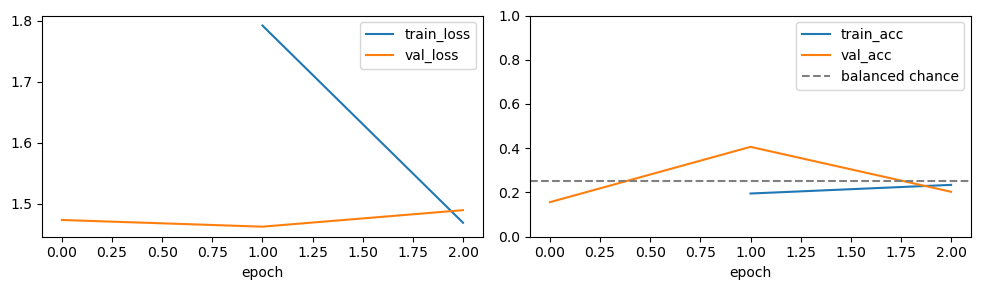

87

In [15]:
def build_vit():
    return timm.create_model('vit_tiny_patch16_224', pretrained=False,
        img_size=CFG['image_size'], depth=CFG['depth'], embed_dim=CFG['embed_dim'],
        num_heads=CFG['num_heads'], num_classes=4, drop_path_rate=0.0).to(DEVICE)

seed_all(CFG['seed'])
model = build_vit()
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'Tokens per image: {model.patch_embed.num_patches} patches + 1 CLS')
print('All parameters on:', {p.device.type for p in model.parameters()})

def loader_for(split, shuffle=False):
    return DataLoader(TensorDataset(X[split], Y[split]), batch_size=CFG['batch_size'],
                      shuffle=shuffle, num_workers=0, pin_memory=False)

@torch.no_grad()
def evaluate_classifier(net, split):
    net.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for xb, yb in loader_for(split):
        logits = net(xb)
        loss_sum += nn.functional.cross_entropy(logits, yb, reduction='sum').item()
        correct += (logits.argmax(1) == yb).sum().item()
        count += len(yb)
    return loss_sum / count, correct / count

def save_vit(epoch):
    torch.save(dict(model=model.state_dict(), epoch=epoch),
               RUN_DIR / 'vit' / f'epoch_{epoch:03d}.pt')

def read_own_checkpoint(path):
    # These files are created by this notebook. The fallback supports older torch.
    try:
        return torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        return torch.load(path, map_location='cpu')

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['vit_lr'], weight_decay=CFG['weight_decay'])
save_vit(0)
initial_loss, initial_acc = evaluate_classifier(model, 'val')
history = [dict(epoch=0, train_loss=np.nan, train_acc=np.nan,
                val_loss=initial_loss, val_acc=initial_acc, seconds=0.0)]
t0 = time.perf_counter()
for epoch in range(1, CFG['vit_epochs'] + 1):
    epoch_start = time.perf_counter()
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for step, (xb, yb) in enumerate(loader_for('train', shuffle=True)):
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = nn.functional.cross_entropy(logits, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        count += len(yb)
        if epoch == 1 and step == min(2, math.ceil(len(Y['train']) / CFG['batch_size']) - 1):
            rate = (time.perf_counter() - epoch_start) / (step + 1)
            estimate = rate * math.ceil(len(Y['train']) / CFG['batch_size']) * CFG['vit_epochs']
            print(f'Observed {rate:.3f}s/batch; rough backbone training estimate {estimate/60:.1f} min')
    val_loss, val_acc = evaluate_classifier(model, 'val')
    elapsed = time.perf_counter() - epoch_start
    history.append(dict(epoch=epoch, train_loss=loss_sum/count, train_acc=correct/count,
                        val_loss=val_loss, val_acc=val_acc, seconds=elapsed))
    if epoch in EPOCHS:
        save_vit(epoch)
    print(f'epoch {epoch:2d} | train loss {loss_sum/count:.3f} | val accuracy {val_acc:.3f} | {elapsed:.1f}s')
TIMES['vit_training'] = time.perf_counter() - t0
history_df = pd.DataFrame(history)
history_df.to_csv(RUN_DIR / 'training_history.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
history_df.plot(x='epoch', y=['train_loss', 'val_loss'], ax=axes[0])
history_df.plot(x='epoch', y=['train_acc', 'val_acc'], ax=axes[1])
axes[1].axhline(0.25, color='gray', ls='--', label='balanced chance')
axes[1].set_ylim(0, 1)
axes[1].legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'figures' / 'classifier_training.png', dpi=120)
plt.show()

LOG_PATH = RUN_DIR / "logs" / "log.txt"
LOG_PATH.write_text(
    "".join(f"Epoch {int(row.epoch)} Val Acc {row.val_acc:.10f}\n"
            for row in history_df.itertuples()),
    encoding="utf-8",
)


## 5. Setting up the pipeline's experiment paths

`ind_name="shapes3d_cpu"` is an experiment tag for the same Shapes3D images. It selects
the loader's existing numeric-label format (`*_y.npy`).

The checkpoint directory deliberately follows the pipeline's parent-directory
convention. `vit_size` is its legacy MLP-width setting, so it is `4 * embed_dim`.

**FULL MODE:**
Prepare a folder with the trained ViT checkpoints in .yml file with appropriate paths

```bash
checkpoint_folder: sae_checkpoints
plots_dir: figs/sae_similarity
results_dir: eval_results
vit_checkpoint_dir: ./results/vit_tiny_ffcv
activation_root: #can be left empty
data_dir: /gpfs/space/projects/mlgroup/data/images_largescale/ #/tmp/imagenet_1k/
imglist_path: /gpfs/space/projects/mlgroup/data/benchmark_imglist/imagenet/test_imagenet.txt #train_imagenet.txt
log_path: #can be left empty
```


In [16]:
DATASET_TAG = "shapes3d_cpu"
SEED_TAG = f"_s{CFG['seed']}"
EXPERIMENT_TAG = f"vit_{DATASET_TAG}{SEED_TAG}"
ACTIVATION_ROOT = RUN_DIR / "activations"
SAE_EXPERIMENT_DIR = RUN_DIR / "sae_checkpoints" / EXPERIMENT_TAG
EVO_DIR = SAE_EXPERIMENT_DIR / "evo_patterns"
IMAGE_DIR = RUN_DIR / "images"
IMGLIST_PATH = RUN_DIR / "imglists" / f"test_{DATASET_TAG}.txt"

BASE_ARGS = dict(
    backbone="vit", ind_name=DATASET_TAG, seed=SEED_TAG, step=0,
    activation_root=str(ACTIVATION_ROOT),
    train_device="cpu", eval_device="cpu",
    train_split="train", eval_split="test", keywords=["train", "test"],
    norm=True, trained_on="cls", train_patches=False, test_patches=False,
    fixed_sae=False, sae_runs=1, skip_existing=False, cache_activations=False,
    run_seed_base=CFG["seed"] + 1000,
    sae_type="batch_top_k_sae", tied=False, circuits=True,
    expansion_coef=CFG["sae_expansion"], k=CFG["sae_k"],
    sae_epochs=CFG["sae_epochs"], batch_size=CFG["sae_batch_size"],
    lr=CFG["sae_lr"], l1_lambda=0.0, l2_lambda=CFG["sae_z_l2"],
    verbose_every=0, vit_size=4 * CFG["embed_dim"], num_heads=CFG["num_heads"],
    num_classes=4, img_size=CFG["image_size"], total_vit_epochs=CFG["vit_epochs"],
    pretrained_vit_IN1K=False, log_path=str(LOG_PATH),
    data_dir=str(IMAGE_DIR), imglist_path=str(IMGLIST_PATH),
    align_method="spearman", align_min_sim=0.05,
    align_compute_stability=False, align_compute_chance=False,
    topk_k=min(20, CFG["n_analysis"]), topk_metric="jaccard",
    topk_threshold=None, topk_act_threshold=0.0, topk_ranking="cls",
    combined=True, combined_images=True, concept_types=False, tag="_cls_only",
)

def args_for_reference(reference):
    epoch, layer = reference
    name = f"refepoch_{epoch}_reflayer_{layer}"
    checkpoint_folder = SAE_EXPERIMENT_DIR / name
    return dict(
        BASE_ARGS, ref_epoch=epoch, ref_layer=layer,
        checkpoint_folder=str(checkpoint_folder),
        results_dir=str(checkpoint_folder / "eval_results"),
        plots_dir=str(RUN_DIR / "figures" / EXPERIMENT_TAG / name),
    )

PIPELINE_ARGS = args_for_reference(REF)
(RUN_DIR / "pipeline_config.yaml").write_text(
    yaml.safe_dump(PIPELINE_ARGS, sort_keys=False), encoding="utf-8"
)
print("Activation store:", ACTIVATION_ROOT / EXPERIMENT_TAG)
print("SAE checkpoint example:", tracking._checkpoint_path(PIPELINE_ARGS, *REF, 0))
print("Pipeline evolution files:", EVO_DIR)


Activation store: C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4\activations\vit_shapes3d_cpu_s42
SAE checkpoint example: C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4\sae_checkpoints\vit_shapes3d_cpu_s42\vit_batch_top_k_sae_run0_seed_s42_epoch2_step0_layer4_regTrue_tiedFalse_epochs3_k16_exp2_trained_cls.pt
Pipeline evolution files: C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4\sae_checkpoints\vit_shapes3d_cpu_s42\evo_patterns


## 6. Export activation arrays and an ordered image list

For each saved backbone, write:

```text
activations/vit_shapes3d_cpu_s42/epoch1_step0/
    vit_shapes3d_cpu_train.npy         # raw [SAE training images, blocks, width]
    vit_shapes3d_cpu_train_y.npy       # shape labels
    vit_shapes3d_cpu_train_logits.npy
    vit_shapes3d_cpu_train_ids.npy     # extra row-identity sidecar
    vit_shapes3d_cpu_train_factors.npy # extra six-factor sidecar
    ... val and test files ...
```

The `.npy` activation layout, split suffixes and label/logit filenames match
`load_all_data`. Save **raw** representations: normalization belongs to the repository
loader. The loader selects a layer on reading. 

Export PNGs and a `<relative_filename> <class_id>` image list in the exact same order
as `test.npy`. This lets the existing pattern plotter load Shapes3D images from disk.

**FULL MODE:**

Activation storing has been resolved already with the experiment script `sae_track_method.py` that uses the `sae_track_method.py/generate_acts_vit_fun_tiny.py` for that in `sae_track_method.py/_load_all_data_cahed(...)` call initiated by `sae_track_method.py/_train_all_saes(...)`. 

In [17]:
t0 = time.perf_counter()
rng = np.random.default_rng(CFG["seed"] + 3)
SAE_FIT_ROWS = np.sort(rng.choice(len(Y["train"]), CFG["n_sae_train"], replace=False))
SAE_VAL_ROWS = np.sort(rng.choice(len(Y["val"]), CFG["n_sae_val"], replace=False))
np.savez(RUN_DIR / "sae_fit_rows.npz", train=SAE_FIT_ROWS, val=SAE_VAL_ROWS)
EXPORT_SPLITS = {
    "train": ("train", SAE_FIT_ROWS),
    "val": ("val", SAE_VAL_ROWS),
    "test": ("analysis", np.arange(len(Y["analysis"]))),
}
EXPORT_IDS = {
    split: SPLIT_IDS[source][rows]
    for split, (source, rows) in EXPORT_SPLITS.items()
}

def activation_prefix(epoch, split):
    return (ACTIVATION_ROOT / EXPERIMENT_TAG / f"epoch{epoch}_step0"
            / f"vit_{DATASET_TAG}_{split}")

for epoch in EPOCHS:
    model.load_state_dict(
        read_own_checkpoint(RUN_DIR / "vit" / f"epoch_{epoch:03d}.pt")["model"],
        strict=True,
    )
    for split, (source, rows) in EXPORT_SPLITS.items():
        loader = DataLoader(TensorDataset(X[source][rows]), batch_size=CFG["batch_size"],
                            shuffle=False, num_workers=0)
        cls_chunks, logit_chunks = [], []
        for (xb,) in loader:
            cls, patches, logits = collect_hidden_states_timm(model, xb, need_patches=False)
            assert patches is None
            cls_chunks.append(cls.cpu())
            logit_chunks.append(logits.cpu())
        raw = torch.cat(cls_chunks).numpy().astype(np.float32)
        logits_np = torch.cat(logit_chunks).numpy()
        assert raw.shape == (len(rows), CFG["depth"], CFG["embed_dim"])
        prefix = activation_prefix(epoch, split)
        prefix.parent.mkdir(parents=True, exist_ok=True)
        np.save(str(prefix) + ".npy", raw)
        np.save(str(prefix) + "_y.npy", Y[source][rows].numpy())
        np.save(str(prefix) + "_logits.npy", logits_np)
        np.save(str(prefix) + "_ids.npy", EXPORT_IDS[split])
        np.save(str(prefix) + "_factors.npy", FACTORS[source][rows])
    print("Exported checkpoint", epoch)

image_lines = []
for row, image_id in enumerate(EXPORT_IDS["test"]):
    filename = f"shape_{int(image_id):06d}.png"
    PILImage.fromarray(RGB["analysis"][row]).save(IMAGE_DIR / filename)
    image_lines.append(f"{filename} {int(Y['analysis'][row])}\n")
IMGLIST_PATH.write_text("".join(image_lines), encoding="utf-8")

def load_disk_data(epoch, layer, splits=("train", "test")):
    # All arrays are loaded by the repository, with its normalization behavior.
    return load_all_data(
        epoch, BASE_ARGS["step"], BASE_ARGS["seed"], BASE_ARGS["norm"], list(splits),
        layer_nr=layer, backbone=BASE_ARGS["backbone"], ind_name=DATASET_TAG,
        train_patches=False, test_patches=False,
        activation_root=BASE_ARGS["activation_root"],
    )

# Verify sample identity/order at every point before matching.
for epoch in EPOCHS:
    for split, (source, rows) in EXPORT_SPLITS.items():
        prefix = activation_prefix(epoch, split)
        np.testing.assert_array_equal(np.load(str(prefix) + "_ids.npy"), EXPORT_IDS[split])
        np.testing.assert_array_equal(np.load(str(prefix) + "_y.npy"), Y[source][rows].numpy())
sample = load_disk_data(EPOCHS[0], LAYERS[0])
np.testing.assert_allclose(
    np.linalg.norm(sample["test"]["activations"], axis=1), 1.0, atol=2e-6
)
TIMES["activation_export"] = time.perf_counter() - t0
del cls_chunks, logit_chunks, raw, logits_np, cls, logits, sample
print("Exported", len(image_lines), "ordered test images and matching image-list rows.")


Exported checkpoint 1
Exported checkpoint 2
(128, 192)
(64, 192)
Exported 64 ordered test images and matching image-list rows.


## 7. Train the pipeline's SAE grid and reload its checkpoints

`train_sae_grid` reads the exported files through `_load_all_data_cached` and writes
the exact names returned by `_checkpoint_path`. Use the existing `train_sae_fast`
trainer for all grid points to avoid the other trainer's 16-worker DataLoader on CPU.
The pipeline's common initialization seed per run is retained; each grid point still
gets a separate SAE fitted on that point's activations.

Reconstruction uses `sae(batch)` and its gated code. Tracking uses `sae.encode(x)`,
which currently returns the ungated ReLU readout for BatchTopK. Reconstruction metrics
use a fixed validation batch size because BatchTopK gating depends on the batch. Here the quality of the trained SAEs is demonstrated via several measures. E.g. FVU measures reconstruction quality.

**FULL MODE:**

Training the SAEs has been resolved already with the experiment script `sae_track_method.py` that uses the `sae_track_method.py/train_all_saes(...)` function for that. 

In [18]:
def reconstruction_metrics(sae, x):
    sae.eval()
    squared_error, active_count = 0.0, 0
    ever_active = torch.zeros(sae.encoder.out_features, dtype=torch.bool)
    with torch.no_grad():
        for batch in x.split(CFG['sae_batch_size']):
            recon, sparse_z = sae(batch)
            squared_error += (recon - batch).square().sum().item()
            active_count += (sparse_z > 0).sum().item()
            ever_active |= (sparse_z > 0).any(0)
    mean_baseline_error = (x - x.mean(0)).square().sum().item()
    return dict(mse=squared_error/x.numel(),
                fvu=squared_error/max(mean_baseline_error, 1e-12),
                mean_l0=active_count/len(x),
                inactive_fraction=(~ever_active).float().mean().item())

t0 = time.perf_counter()
with capture_output() as captured:
    sae_paths = tracking.train_sae_grid(
        PIPELINE_ARGS, EPOCHS, LAYERS, *REF,
        load_data=lambda epoch, layer: tracking._load_all_data_cached(
            epoch, layer, PIPELINE_ARGS, None
        ),
        checkpoint_path=lambda epoch, layer, run_idx: tracking._checkpoint_path(
            PIPELINE_ARGS, epoch, layer, run_idx
        ),
        trainer=train_sae_fast,
    )
(RUN_DIR / "logs" / "sae_training.log").write_text(
    captured.stdout + captured.stderr, encoding="utf-8"
)

SAES, USED_IN_FIT, quality_records = {}, {}, []
for epoch in EPOCHS:
    for layer in LAYERS:
        with contextlib.redirect_stdout(io.StringIO()):
            data = load_disk_data(epoch, layer, ("train", "val"))
        fit_x = torch.from_numpy(data["train"]["activations"])
        val_x = torch.from_numpy(data["val"]["activations"])
        path = tracking._checkpoint_path(PIPELINE_ARGS, epoch, layer, 0)
        assert path == sae_paths[(0, epoch, layer)] and path.is_file()
        sae = load_checkpoint(path, device="cpu").eval()
        SAES[(epoch, layer)] = sae
        metrics = reconstruction_metrics(sae, val_x)
        used = torch.zeros(sae.encoder.out_features, dtype=torch.bool)
        with torch.no_grad():
            for batch in fit_x.split(CFG["sae_batch_size"]):
                _, sparse_z = sae(batch)
                used |= (sparse_z > 0).any(0)
        USED_IN_FIT[(epoch, layer)] = used.numpy()
        quality_records.append(dict(epoch=epoch, layer=layer, **metrics))
        print(f"SAE e={epoch}, l={layer}: validation FVU {metrics['fvu']:.3f}, L0 {metrics['mean_l0']:.1f}")
quality_df = pd.DataFrame(quality_records)
quality_df.to_csv(RUN_DIR / "analysis" / "sae_quality.csv", index=False)
np.savez(RUN_DIR / "analysis" / "selected_in_fit.npz",
         **{f"e{e}_l{l}": mask for (e, l), mask in USED_IN_FIT.items()})
TIMES["sae_fitting"] = time.perf_counter() - t0
display(quality_df.groupby("epoch")[["mse", "fvu", "mean_l0", "inactive_fraction"]].mean())
print("FVU < 1 beats a validation-mean baseline; it does not establish interpretability.")


SAE e=1, l=0: validation FVU 1.266, L0 16.0
SAE e=1, l=1: validation FVU 1.297, L0 16.0
SAE e=1, l=2: validation FVU 1.333, L0 16.0
SAE e=1, l=3: validation FVU 1.360, L0 16.0
SAE e=1, l=4: validation FVU 1.318, L0 16.0
SAE e=2, l=0: validation FVU 1.240, L0 16.0
SAE e=2, l=1: validation FVU 1.264, L0 16.0
SAE e=2, l=2: validation FVU 1.279, L0 16.0
SAE e=2, l=3: validation FVU 1.313, L0 16.0
SAE e=2, l=4: validation FVU 1.287, L0 16.0


,mse,fvu,mean_l0,inactive_fraction
epoch,,,,
1,0.004164,1.314553,16.0,0.789062
2,0.004199,1.276574,16.0,0.796875


FVU < 1 beats a validation-mean baseline; it does not establish interpretability.


## 8. Run combined evaluation, then reload its file

Call `_evaluate_run_combined` with the same arguments as the experiment script.
It loads activations and checkpoints itself and writes:

```text
sae_checkpoints/vit_shapes3d_cpu_s42/evo_patterns/
    evolution_patterns_e12_l4.npz
```

The saved keys are `cor_res`, `top_res`, `concepts`, `epochs`, `cka`, and `pre_loss`.
For each source feature, combined matching takes the maximum of its best match in an
independently trained target SAE and its corresponding fixed-SAE readout. All target
features participate, as in the pipeline. 

`pre_loss` is reconstruction by the **reference SAE** on each target's analysis
activations, not the independent SAE validation loss above.

**FULL MODE:**

Flagging `combined: True` in the .yml file, uses the `sae_track_method.py/_evaluate_run_combined()` as both independent SAE and fixed SAE scores are availabel. In case of of only fixed SAE evaluation, use `fixed_sae: True` flag and for independent mark both `combined: False` and `fixed_sae: False` (in this case `sae_track_method.py/_evaluate_run` will be used instead).



In [ ]:
t0 = time.perf_counter()

def run_pipeline_reference(reference):
    args = args_for_reference(reference)
    config_dir = Path(args["results_dir"]) / "run_0"
    config_dir.mkdir(parents=True, exist_ok=True)
    (config_dir / "config.yaml").write_text(yaml.safe_dump(args, sort_keys=False), encoding="utf-8")
    with capture_output() as captured:
        tracking._evaluate_run_combined(0, args, EPOCHS, LAYERS, *reference, None)
    plt.close("all")
    log = RUN_DIR / "logs" / f"evaluate_e{reference[0]}_l{reference[1]}.log"
    log.write_text(captured.stdout + captured.stderr, encoding="utf-8")
    path = EVO_DIR / f"evolution_patterns_e{reference[0]}_l{reference[1]}.npz"
    if not path.is_file():
        raise RuntimeError(f"The pipeline did not write {path}")
    with capture_output() as captured:
        tracking._save_concept_evo_pattern(
            0, args, EPOCHS, LAYERS, *reference,
            method="max", want_images=True, eval_device="cpu",
        )
    plt.close("all")
    return path

reference_path = run_pipeline_reference(REF)
with np.load(reference_path, allow_pickle=False) as stored:
    evolution = {key: stored[key].copy() for key in stored.files}

TIMES["reference_evaluation"] = time.perf_counter() - t0
print("Reloaded pipeline result:", reference_path)
print({key: value.shape for key, value in evolution.items()})


Reloaded pipeline result: C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4\sae_checkpoints\vit_shapes3d_cpu_s42\evo_patterns\evolution_patterns_e1_l2.npz
{'cor_res': (384, 5, 2), 'top_res': (384, 5, 2), 'concepts': (384, 3), 'epochs': (2,), 'cka': (5, 2), 'pre_loss': (5, 2)}


## 9. Let the pipeline reload and plot the saved patterns

The plotter reads the same `.npz`, checkpoint, activations, `Val Acc` log, PNG files
and image list that the script uses. It keeps its existing first-61-feature limit and
activation/entropy filters. Some small smoke runs may produce only the loss/CKA
report; no synthetic pattern is substituted when a feature fails those filters.

`pattern_images=False` skips the extra per-class galleries. The pipeline's pattern
heatmaps still include their low/mid/high image strip. Only a few saved figures are
displayed inline; the rest remain on disk.

**FULL MODE:**

Flagging `combined_images: True` in the .yml file, uses the `sae_track_method.py/save_concept_evo_pattern(...)` as both independent SAE and fixed SAE scores are available. In case of only fixed or independent SAEs plotting, mark `combined_images: False` (in this case `sae_track_method.py/_save_concept_plots(...)` will be used instead). Flag `want_images: True` if the top activated class top activated images plots are desired as well. In case, only plots are wanted and the activations are already computed, use `only_plots: True`.

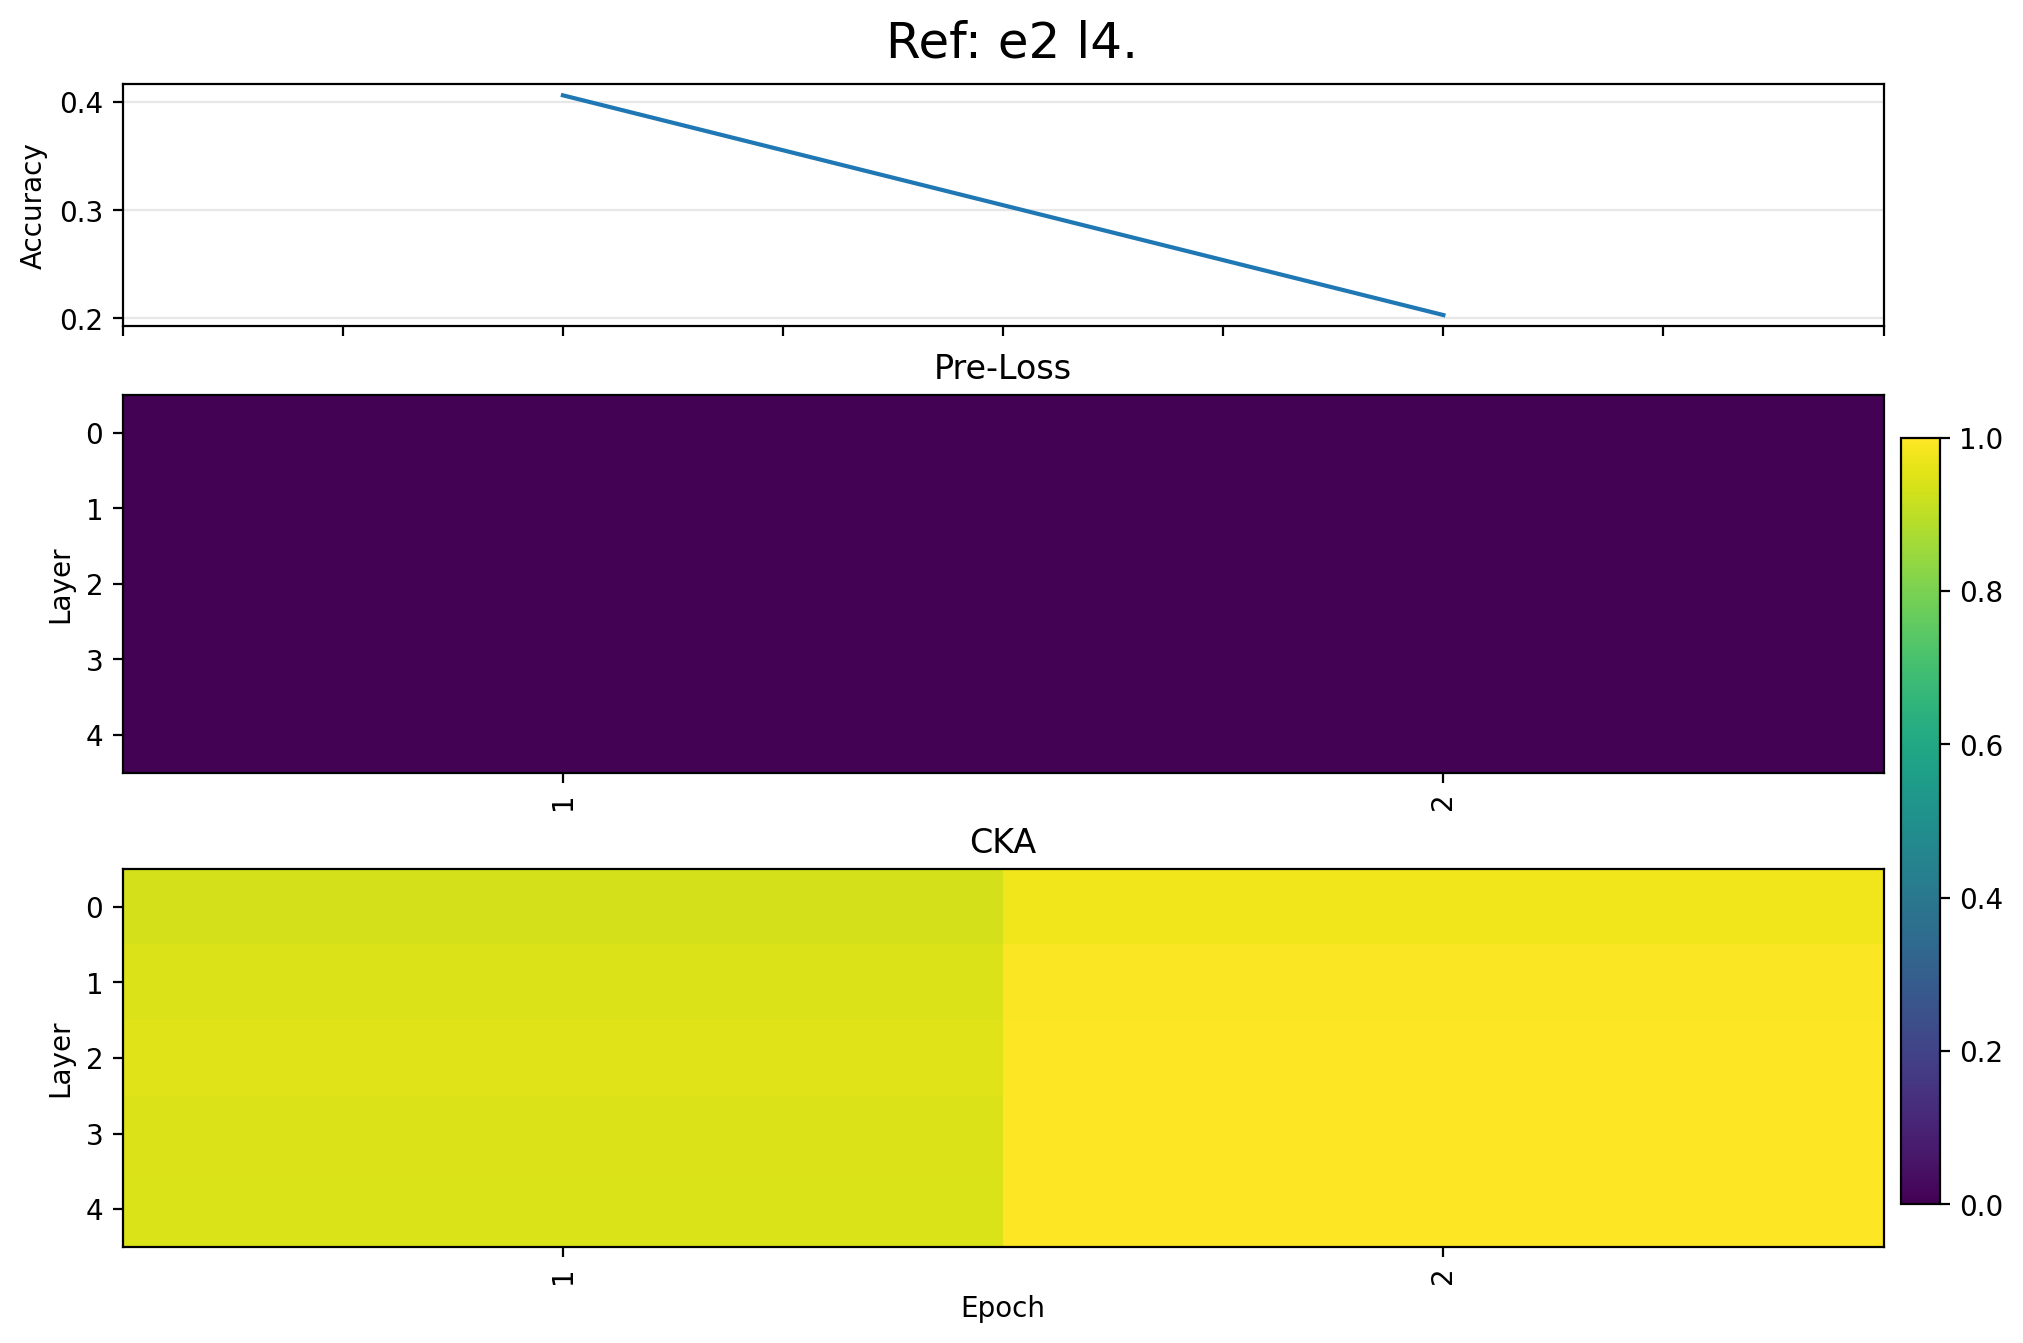

Saved 0 feature-pattern reports in C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4\figures\vit_shapes3d_cpu_s42\refepoch_2_reflayer_4\run_0\combined__cls_only


In [29]:
t0 = time.perf_counter()
with capture_output() as captured:
    tracking._save_concept_evo_pattern(
        0, PIPELINE_ARGS, EPOCHS, LAYERS, *REF,
        method="max", want_images=CFG["pattern_images"], eval_device="cpu",
    )
plt.close("all")
(RUN_DIR / "logs" / "pattern_plots.log").write_text(
    captured.stdout + captured.stderr, encoding="utf-8"
)
PATTERN_DIR = Path(PIPELINE_ARGS["plots_dir"]) / "run_0" / f"combined_{PIPELINE_ARGS['tag']}"
loss_figure = PATTERN_DIR / f"losses_ckas_ref_e{REF[0]}_l{REF[1]}.png"
pattern_paths = sorted(PATTERN_DIR.glob(f"max_run_0_ref_e{REF[0]}_l{REF[1]}_concept*.png"))
if loss_figure.is_file():
    display(NotebookImage(filename=str(loss_figure)))
else:
    raise RuntimeError(f"Missing loss/CKA plot. Read {RUN_DIR / 'logs' / 'pattern_plots.log'}")
for path in pattern_paths[:2]:
    display(NotebookImage(filename=str(path)))
print(f"Saved {len(pattern_paths)} feature-pattern reports in {PATTERN_DIR}")
TIMES["pattern_plots"] = time.perf_counter() - t0


## 10. Generate and aggregate the pipeline's reference files

Evaluate each requested reference using the same saved SAE grid. Then call
`compute_scores_for_reference_grid` with the **directory of pipeline `.npz` files**.
That function reloads `cor_res`, `concepts` and `epochs`, applies its existing
`sparsity > 0.001` inclusion rule, and calls the repository's concept/aggregate scorers.
Here `sparsity` means fraction of positive readouts.

The short grid uses two-checkpoint onset/disappearance windows and smaller
layer-distance thresholds than the 12-layer ImageNet experiment. These are explicit
analysis parameters, not changes to the scoring implementation. Smoke-run classes
should not be interpreted as evidence of learned semantic migration.

**FULL MODE:**

To run the full pipeline, prepare the settings in `sae_exp_config_base.yml` and run the following bash script (`sae_tracking_exp_large.sh` or `sae_tracking_exp_large_cpu.sh`) with appropriate lists of checkpoints.

To get the aggregate evolution patterns figures, one has to adjust the hardcoded paths in the .py file and then launch it 
```bash
python -u evo_aggregate_patterns.py
```


In [34]:
t0 = time.perf_counter()
REFERENCE_EPOCHS = EPOCHS if CFG["all_reference_analysis"] else [REF[0]]
REFERENCE_LAYERS = LAYERS if CFG["all_reference_analysis"] else [REF[1]]
for epoch in REFERENCE_EPOCHS:
    for layer in REFERENCE_LAYERS:
        if (epoch, layer) != REF:
            run_pipeline_reference((epoch, layer))
        print("Pipeline result ready:", (epoch, layer))


SCORE_KWARGS = dict(
    input_layout="NLT", onset_k=2, disappearance_k=2,
    start_end_fraction=0.25, drift_threshold_layers=0.5,
    min_directional_efficiency=0.35, min_layer_localization=0.15,
    max_width=max(1.0, (len(LAYERS) - 1) * 0.6), choice="com",
)
(RUN_DIR / "analysis" / "score_config.json").write_text(
    json.dumps(SCORE_KWARGS, indent=2)
)
with capture_output() as captured:
    all_scores_df, summary_df = repo_metrics.compute_scores_for_reference_grid(
        similarity_source=str(EVO_DIR),
        reference_epochs=REFERENCE_EPOCHS, reference_layers=REFERENCE_LAYERS,
        layer_values=LAYERS, denominator="all", **SCORE_KWARGS,
    )
(RUN_DIR / "logs" / "aggregation.log").write_text(
    captured.stdout + captured.stderr, encoding="utf-8"
)
all_scores_df.to_csv(RUN_DIR / "analysis" / "all_reference_feature_metrics.csv", index=False)
summary_df.to_csv(RUN_DIR / "analysis" / "all_reference_summary.csv", index=False)
feature_scores = all_scores_df[
    (all_scores_df["reference_epoch"] == REF[0])
    & (all_scores_df["reference_layer"] == REF[1])
].copy()
feature_scores.to_csv(RUN_DIR / "analysis" / "reference_migration_metrics.csv", index=False)
display(feature_scores[[
    "concept_id", "has_emerged", "emergence_epoch",
    "signed_mean_drift_active", "mean_layer_width", "drift_class",
]].head(12))


Pipeline result ready: (1, 0)
Pipeline result ready: (1, 1)
Pipeline result ready: (1, 2)
Pipeline result ready: (1, 3)
Pipeline result ready: (1, 4)
Pipeline result ready: (2, 0)
Pipeline result ready: (2, 1)
Pipeline result ready: (2, 2)
Pipeline result ready: (2, 3)
Pipeline result ready: (2, 4)


,concept_id,has_emerged,emergence_epoch,signed_mean_drift_active,mean_layer_width,drift_class
2827,0,True,1.0,0.033240,1.411707,diffuse
2828,1,True,1.0,-0.027033,1.407783,diffuse
2829,2,True,1.0,-0.004764,1.417199,diffuse
2830,3,True,1.0,0.049060,1.413509,diffuse
2831,5,True,1.0,0.029148,1.415428,diffuse
2832,7,True,1.0,-0.003193,1.421523,diffuse
2833,8,True,1.0,0.141450,1.409498,diffuse
2834,9,True,1.0,0.004263,1.412569,diffuse
2835,10,True,1.0,0.030682,1.417261,diffuse
2836,11,True,1.0,0.074459,1.419836,diffuse


In [ ]:

metrics = [
        "emergence_rate_pct",
        "disappearance_pct_emerged",
        "mean_active_lifetime_duration",
        "mean_persistence_fraction_after_emergence",
        "deeper_migratory_pct",
        "earlier_migratory_pct",
        "stable_pct",
        "wandering_pct",
        "reference_anchor_match_pct_among_sticky",
        "mean_layer_width_norm",
        "mean_layer_entropy",
        "mean_label_entropy",
        "mean_signed_mean_drift_active",
        "mean_signed_median_drift_active",
        "spread_concepts_pct",
        "n_valid_drift",
        "n_concepts",
        "n_emerged",
        "disappearance_pct_all",
        "mean_emergence_epoch",
        "mean_disappearance_epoch",
        "mean_active_lifetime_fraction",
        "mean_persistence_fraction_until_disappearance",
        "migratory_pct",
        "reference_anchor_match_pct_all",
        "mean_reference_layer_stickiness",
        "mean_stabel_to_anchor",
        "mean_layer_width",
        "mean_layer_localization",
        "mean_directional_efficiency",
        "mean_path_active",
        "mean_strength_salience",
        "mean_peak_strength",
        "mean_sparsity",
        "mean_activation",
    ]
figures = repo_metrics.plot_aggregate_heatmaps(
    summary_df,
    metrics=metrics,
    reference_epochs=REFERENCE_EPOCHS, reference_layers=REFERENCE_LAYERS,
    save_path=str(RUN_DIR / "figures" / "aggregate"),
    dpi=130, close_after_save=True, datasettag="Shapes3D CPU",
)
for figure in figures.values():
    display(figure)
display(summary_df[["reference_epoch", "reference_layer", "n_concepts",
                    "n_emerged", "earlier_migratory_pct", "deeper_migratory_pct"]])
TIMES["all_reference_analysis"] = time.perf_counter() - t0


## 11. `_track_feature` on one feature

Choose a feature in the earliest trained reference and follow its best matches at the
next saved checkpoints. `TRACK_CONCEPT=None` selects the most variable readout so a
dead feature is not used for the example; set an explicit integer to try another.

This calls the repository function and reloads its JSON from `evo_patterns/tracks/`.
**The original reference SAE and feature stay fixed throughout the track**, matching
the current function's logic. At each target checkpoint, select the layer with the
highest saved combined similarity, then compare the best independent-SAE match with
the original SAE's fixed readout. This is not a recursively re-anchored feature chain.
`matched_sae_epoch/layer` identify the decoder that owns `matched_concept`; a fixed
winner still belongs to the original SAE, even when evaluated on a later layer.

**FULL MODE:**

Flag `track_feature: True` and choose the feature id to track `track_feature_id: 0` in the .yml file and launch `sae_track_method.py` with adjusted .yml to track the feature for x nr of epochs (currently hardcoded to be 50 steps). The function `sae_track_method.py/_track_feature(...)` will save the checkpoints and plot the images.

,step,reference_epoch,reference_layer,reference_concept,epoch,layer,match_kind,matched_concept,matched_sae_epoch,matched_sae_layer,fixed_similarity,independent_similarity,combined_similarity
0,1,1,4,78,2,2,independent,246,2,2,0.895142,0.962616,0.962616


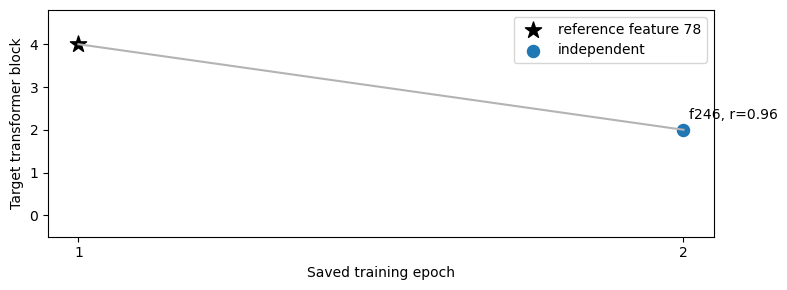

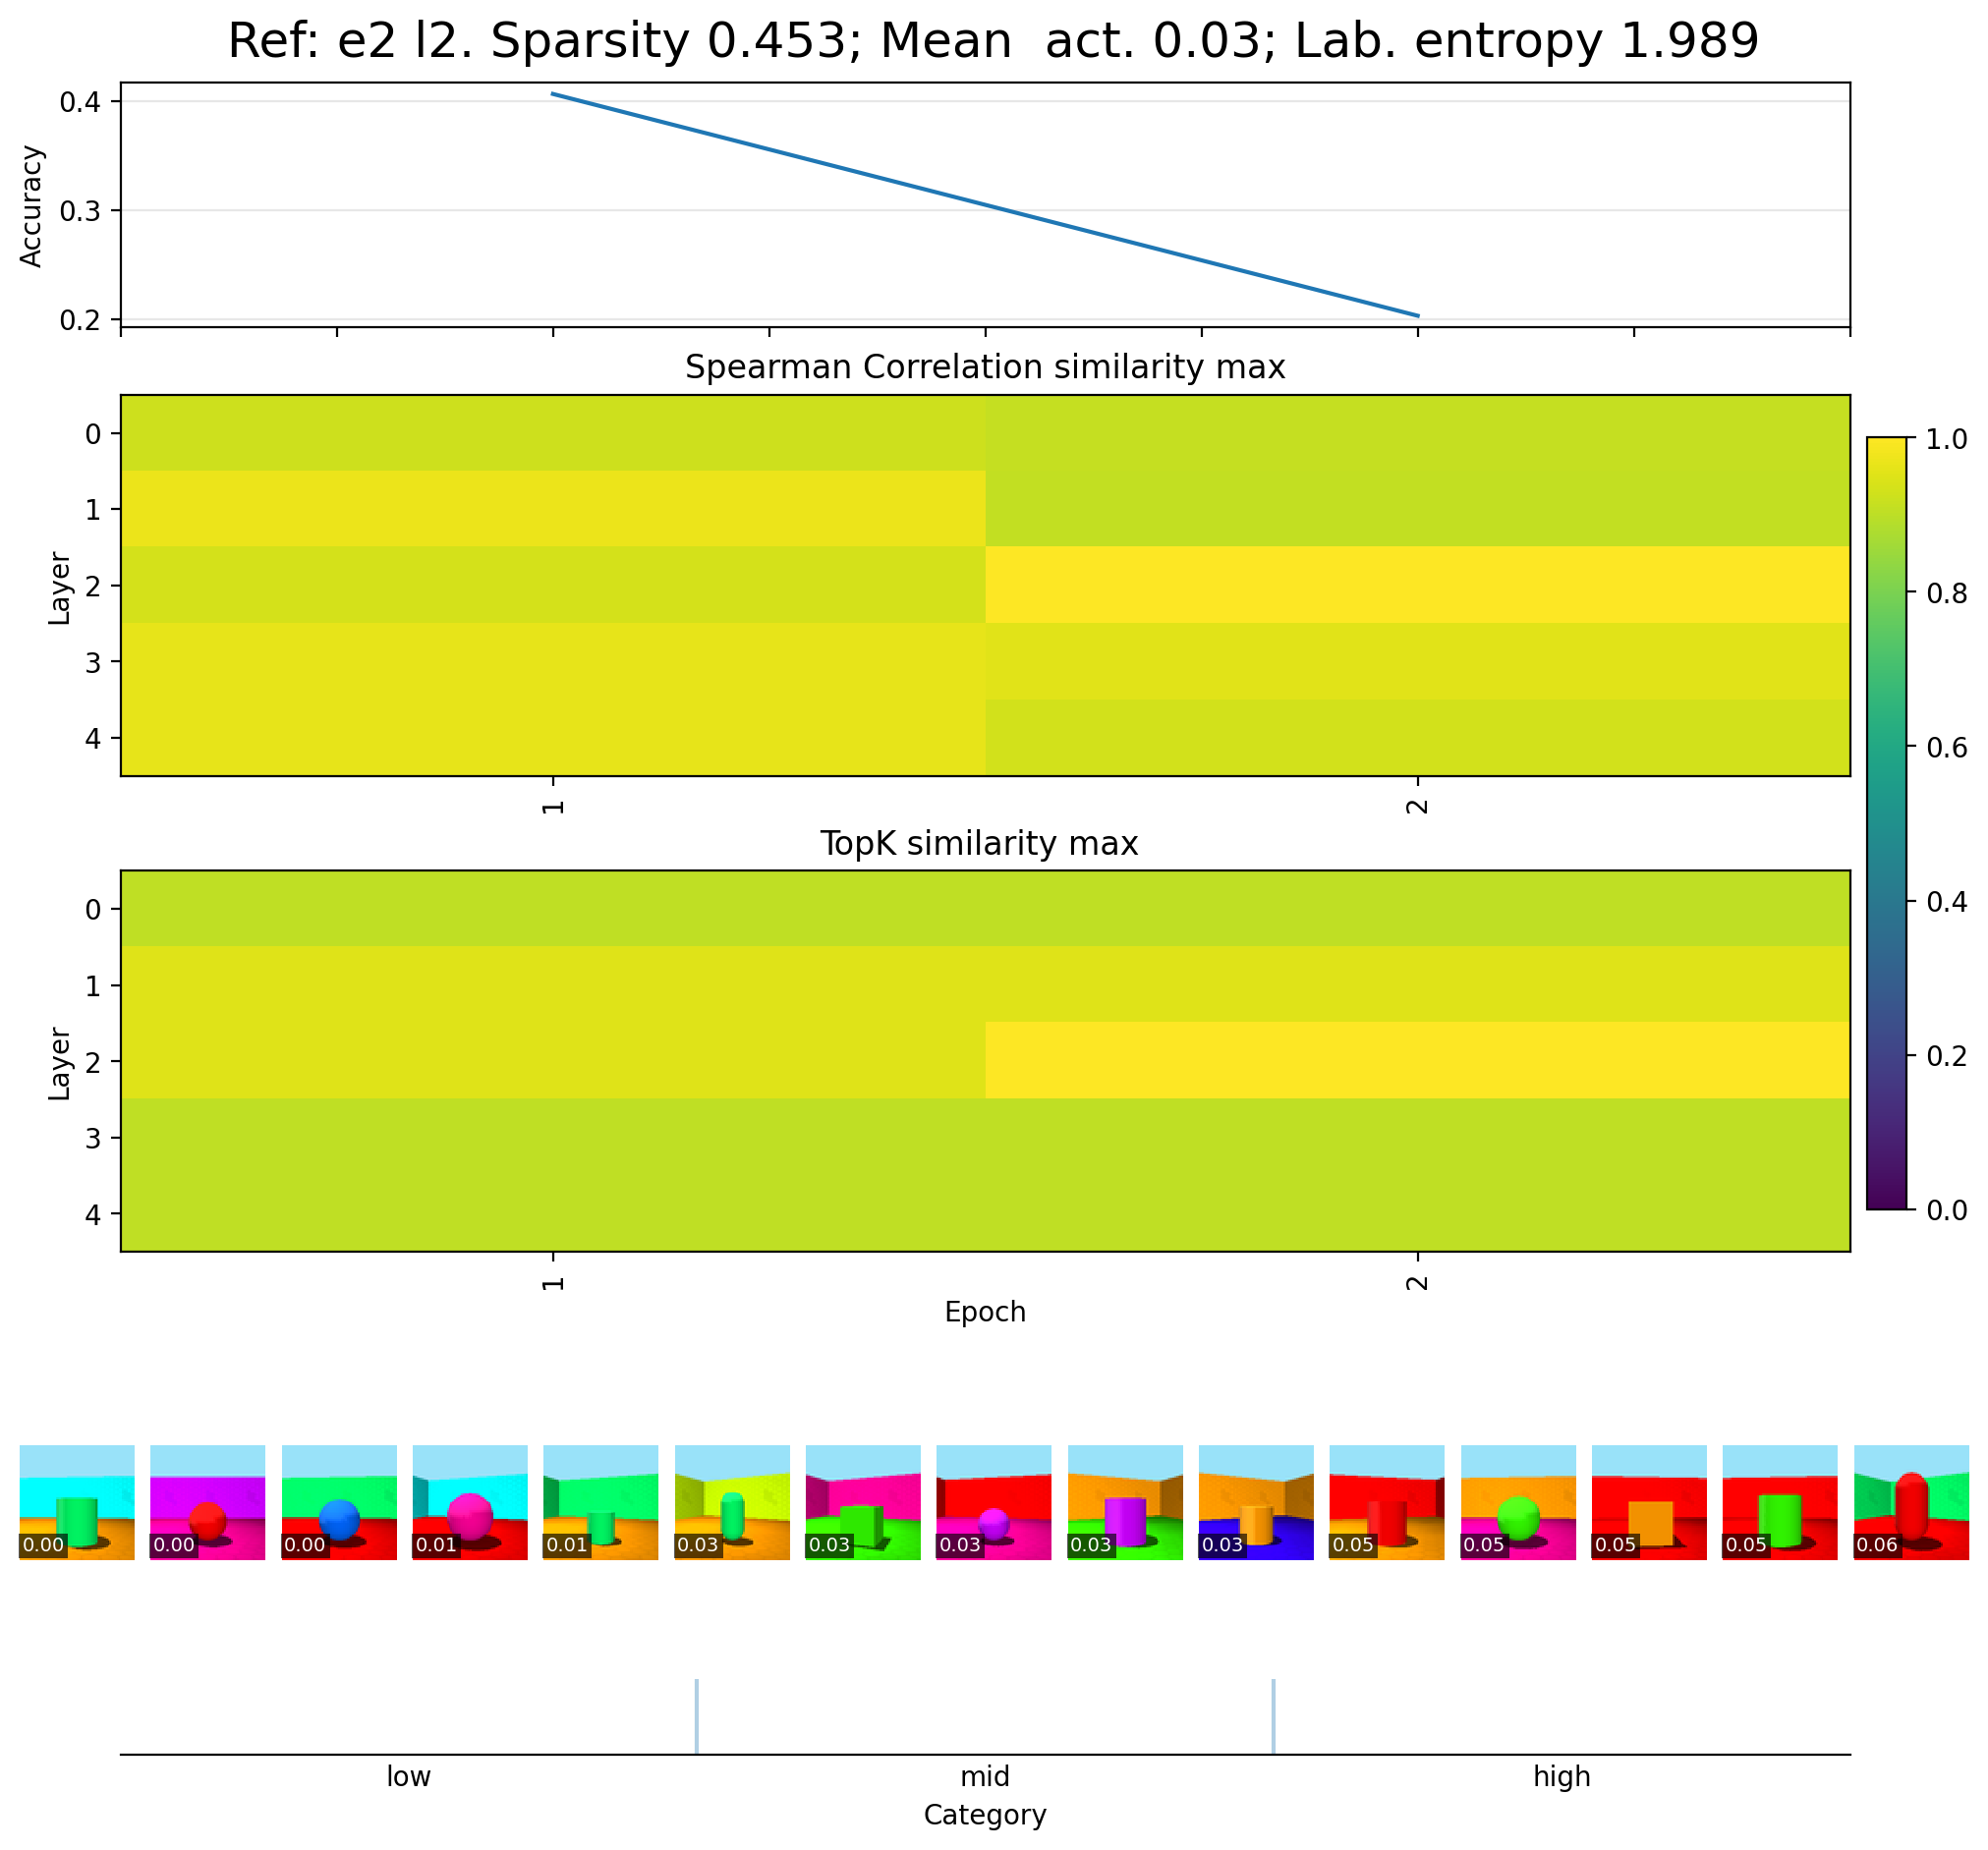

Pipeline feature track: C:\Users\rooben\Documents\TARTU\aPHD\VIT-Feature-Evolution-and-Migration\demo_outputs\shapes3d_cpu\smoke_d_zgkpr4\sae_checkpoints\vit_shapes3d_cpu_s42\evo_patterns\tracks\track_run_0_ref_e1_l4_concept78.json


In [ ]:
t0 = time.perf_counter()
TRACK_REF = (EPOCHS[0], LAYERS[-1])         # Must leave at least one later checkpoint.
TRACK_CONCEPT = None                       # Or an integer in this reference SAE.
TRACK_STEPS = min(CFG["track_steps"], len(EPOCHS) - EPOCHS.index(TRACK_REF[0]) - 1)
track_reference_path = EVO_DIR / f"evolution_patterns_e{TRACK_REF[0]}_l{TRACK_REF[1]}.npz"
if not track_reference_path.is_file():
    run_pipeline_reference(TRACK_REF)
track_args = dict(args_for_reference(TRACK_REF),
                  want_images=CFG["pattern_images"], track_plots=True)
with capture_output():
    track_data = tracking._load_all_data_cached(*TRACK_REF, track_args, None, eval_mode=True)
with torch.no_grad():
    track_codes = SAES[TRACK_REF].encode(torch.from_numpy(track_data).float()).numpy()
if TRACK_CONCEPT is None:
    spread = track_codes.std(axis=0)
    if spread.max() <= 1e-8:
        raise RuntimeError("No varying feature is available for this example; increase training/data.")
    TRACK_CONCEPT = int(spread.argmax())
if not 0 <= TRACK_CONCEPT < track_codes.shape[1]:
    raise ValueError("TRACK_CONCEPT is outside this SAE's code dimension.")
del track_data, track_codes

try:
    with capture_output() as captured:
        tracking._track_feature(
            0, track_args, EPOCHS, LAYERS, *TRACK_REF, None,
            steps=TRACK_STEPS, concept=TRACK_CONCEPT,
        )
finally:
    plt.close("all")
    (RUN_DIR / "logs" / "feature_tracking.log").write_text(
        captured.stdout + captured.stderr, encoding="utf-8"
    )
track_path = (EVO_DIR / "tracks" /
              f"track_run_0_ref_e{TRACK_REF[0]}_l{TRACK_REF[1]}_concept{TRACK_CONCEPT}.json")
track_df = pd.DataFrame(json.loads(track_path.read_text(encoding="utf-8")))
track_df.to_csv(RUN_DIR / "analysis" / "feature_track.csv", index=False)
display(track_df)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot([TRACK_REF[0], *track_df["epoch"]], [TRACK_REF[1], *track_df["layer"]], color="0.7")
ax.scatter(*TRACK_REF, marker="*", s=150, color="black", label=f"reference feature {TRACK_CONCEPT}")
for kind, group in track_df.groupby("match_kind"):
    ax.scatter(group["epoch"], group["layer"], s=75, label=kind)
    for row in group.itertuples():
        ax.annotate(f"f{row.matched_concept}, r={row.combined_similarity:.2f}",
                    (row.epoch, row.layer), xytext=(4, 8), textcoords="offset points")
ax.set(xlabel="Saved training epoch", ylabel="Target transformer block",
       xticks=EPOCHS, yticks=LAYERS, ylim=(LAYERS[0] - 0.5, LAYERS[-1] + 0.8))
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "feature_track.png", dpi=130)
plt.show()

track_plot_dir = Path(track_args["plots_dir"]) / "run_0" / f"combined_{track_args['tag']}"
shown = set()
for row in track_df.itertuples():
    plot = track_plot_dir / (f"max_run_0_ref_e{row.matched_sae_epoch}_l{row.matched_sae_layer}"
                             f"_concept{row.matched_concept}.png")
    if track_args["track_plots"] and not plot.is_file():
        raise RuntimeError(f"Expected requested feature plot: {plot}")
    if plot.is_file() and plot not in shown and len(shown) < 2:
        display(NotebookImage(filename=str(plot)))
        shown.add(plot)
TIMES["feature_tracking"] = time.perf_counter() - t0
print("Pipeline feature track:", track_path)

# TODOs

0) ~~make exact comparisons how to use the pipeline at each cell with conf and sbatch files or commands~~
1) ~~delete the tests~~
2) update the readme
3) ~~make a requirement for this~~
4) ~~make a sbatch file with all the commands for the full pipeline~~
5) ~~0 layer is not needed?~~
6) ~~recursive plotting~~
7) demo
8) ~~fix titles in plotting and make sure its up to date with the repo~~